<a href="https://colab.research.google.com/github/taniavalasky/TCC_Otimizacao_de_Carteira_de_Acoes/blob/main/carteira_30_ativos_modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vamos fazer a extração da carteira

In [20]:
!pip install gurobipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 34.6 MB/s  0:00:00


In [21]:
import numpy as np
import os
import requests
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import yfinance as yf
import random
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import math

Consulta API da BRAPI - contem os ativos listados na B3

Puxa lista completa com valores **(BRAPI + YAHOO)**

In [6]:
# ============================================================
# 1. BUSCAR TODOS OS ATIVOS NA BRAPI
# ============================================================

BASE_URL = "https://brapi.dev/api/v2/tickers"
TOKEN = os.getenv("BRAPI_TOKEN")
headers = {
    "Authorization": f"Bearer {TOKEN}"
} if TOKEN else {}

rows = []
page = 1

while True:
    print(f"Consultando BRAPI - página {page}...")
    response = requests.get(
        BASE_URL,
        params={
            "sortBy": "symbol",
            "sortOrder": "asc",
            "page": page,
            "limit": 100,
        },
        headers=headers,
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    rows.extend(payload.get("results", []))
    pagination = payload.get("pagination", {})
    total_pages = pagination.get("totalPages", page)

    if page >= total_pages:
        break
    page += 1

# ============================================================
# 2. CRIAR DATAFRAME DA BRAPI
# ============================================================

df = pd.DataFrame(rows)
print("\nTotal de ativos encontrados pela BRAPI:")
print(len(df))

# ============================================================
# 3. LIMPAR OS TICKERS
# ============================================================

df = df[
    df["symbol"].notna()
].copy()

df["symbol"] = (
    df["symbol"]
    .astype(str)
    .str.upper()
    .str.strip()
)

# Remove duplicados
df = df.drop_duplicates(
    subset=["symbol"]
).reset_index(drop=True)

# ============================================================
# 4. CLASSIFICAR OS ATIVOS
# ============================================================

def classificar_ativo(row):
    asset_type = str(
        row.get("assetType", "")
    ).lower().strip()
    sub_type = str(
        row.get("subType", "")
    ).lower().strip()

    # Ações
    if sub_type in ["stock", "unit"]:
        return "AÇÃO"
    if asset_type == "stock":
        return "AÇÃO"

    # Fundo Imobiliário
    if sub_type == "fii":
        return "FII"

    # FIAGRO
    if sub_type in ["fi-agro", "fiagro"]:
        return "FIAGRO"

    # FI-Infra
    if sub_type in ["fi-infra", "fiinfra"]:
        return "FI-INFRA"

    # FIP
    if sub_type == "fip":
        return "FIP"

    # FIDC
    if sub_type == "fidc":
        return "FIDC"

    # ETF
    if sub_type == "etf":
        return "ETF"

    # BDR
    if sub_type == "bdr":
        return "BDR"

    return "OUTRO"

df["tipo"] = df.apply(
    classificar_ativo,
    axis=1
)

# ============================================================
# 5. CRIAR TICKER DO YAHOO FINANCE
# ============================================================

df["ticker_yahoo"] = (
    df["symbol"]
    .apply(
        lambda x: x
        if x.endswith(".SA")
        else x + ".SA"
    )
)

# ============================================================
# 6. PEGAR SOMENTE AÇÕES E FIIs
# ============================================================

df_investimentos = df[
    df["tipo"].isin([
        "AÇÃO",
        "FII",
        "FIAGRO"
    ])
].copy()

df_investimentos = (
    df_investimentos
    .drop_duplicates(subset=["ticker_yahoo"])
    .reset_index(drop=True)
)

# Remove o F do mercado fracionário antes de criar o ticker do Yahoo
df_investimentos["symbol_yahoo"] = df_investimentos["symbol"].str.replace(
    r"F$", "",
    regex=True
)

df_investimentos["ticker_yahoo"] = df_investimentos["symbol_yahoo"] + ".SA"

# ============================================================
# 7. CRIAR LISTA PARA O YAHOO FINANCE
# ============================================================

ativos = df_investimentos[
    "ticker_yahoo"
].tolist()

print("\nQuantidade de ações + FIIs + FIAGRO:")
print(len(ativos))
print("\nPrimeiros ativos:")
print(ativos[:20])

# ============================================================
# 8. BAIXAR DADOS DO YAHOO FINANCE
# ============================================================

data = yf.download(
    tickers=ativos,

    # Período desejado
    start="2025-06-01",
    end="2026-06-01",

    # Estrutura por ticker
    group_by="ticker",

    # Preços ajustados
    auto_adjust=True,

    # Não exibir mensagens desnecessárias
    progress=True
)

# ============================================================
# 9. CRIAR BASE FINAL DE PREÇOS
# ============================================================

close_data = pd.DataFrame()

ativos_validos = []
ativos_invalidos = []

for ativo in ativos:
    try:

        # Verifica se o ticker existe no resultado
        if ativo in data.columns.get_level_values(0):

            preco = data[ativo]["Close"]

            # Verifica se existem dados
            if not preco.isna().all():

                close_data[ativo] = preco

                ativos_validos.append(ativo)

            else:

                print(
                    f"Ativo {ativo} removido: "
                    f"não foram encontrados dados."
                )

                ativos_invalidos.append(ativo)

        else:

            print(
                f"Ativo {ativo} não apareceu "
                f"no resultado do Yahoo Finance."
            )

            ativos_invalidos.append(ativo)

    except KeyError:

        print(
            f"Ativo {ativo} não possui "
            f"dados de fechamento."
        )

        ativos_invalidos.append(ativo)

# ============================================================
# 10. LIMPAR BASE
# ============================================================

# Remove somente linhas em que todos os ativos
# estejam sem informação.
close_data = close_data.dropna(
    how="all"
)

close_data.index.name = "Data"

# ============================================================
# 11. RESULTADO
# ============================================================

print("\n")
print("=" * 80)
print("BASE FINAL - YAHOO FINANCE")
print("=" * 80)
print(close_data)
print("\nQuantidade de linhas:")
print(close_data.shape[0])
print("\nQuantidade de ativos encontrados:")
print(close_data.shape[1])

# ============================================================
# 12. ATIVOS VÁLIDOS
# ============================================================

print("\n")
print("=" * 80)
print("ATIVOS UTILIZADOS")
print("=" * 80)
print(ativos_validos)

# ============================================================
# 13. ATIVOS QUE NÃO FORAM ENCONTRADOS
# ============================================================

print("\n")
print("=" * 80)
print("ATIVOS NÃO ENCONTRADOS NO YAHOO")
print("=" * 80)
print(ativos_invalidos)

# ============================================================
# 14. INFORMAÇÕES DA BASE
# ============================================================

print("\n")
print("=" * 80)
print("RESUMO")
print("=" * 80)
print(f"Ativos encontrados pela BRAPI: {len(ativos)}")
print(f"Ativos encontrados no Yahoo: {len(ativos_validos)}")
print(f"Ativos não encontrados no Yahoo: {len(ativos_invalidos)}")

[********              17%                       ]  135 of 776 completed

Consultando BRAPI - página 1...


[*********             18%                       ]  137 of 776 completed

Consultando BRAPI - página 2...
Consultando BRAPI - página 3...


[*********             18%                       ]  141 of 776 completed

Consultando BRAPI - página 4...
Consultando BRAPI - página 5...


... (50 outputs left out)

/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  close_data[ativo] = preco
/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  close_data[ativo] = preco
/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

Ativo VGRH11.SA removido: não foram encontrados dados.
Ativo VTOT11.SA removido: não foram encontrados dados.
Ativo VVDI11.SA removido: não foram encontrados dados.


/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  close_data[ativo] = preco
/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  close_data[ativo] = preco
/tmp/ipykernel_732/2090821799.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



BASE FINAL - YAHOO FINANCE
            AAGR11.SA  AALR3.SA  AAZQ11.SA   ABCB4.SA  ABCP11.SA   ABEV3.SA  \
Data                                                                          
2025-06-02  76.196556      5.68   5.352669  17.875563  72.795799  13.083265   
2025-06-03  76.196556      5.73   5.330521  17.978003  75.593597  13.177322   
2025-06-04  76.188728      5.53   5.323138  18.285316  71.041687  13.243161   
2025-06-05  76.188728      5.66   5.330521  18.242636  75.251572  13.045643   
2025-06-06  76.196556      5.41   5.323138  18.302391  74.620079  13.243161   
...               ...       ...        ...        ...        ...        ...   
2026-05-25  94.813057      3.40   6.799858  23.655987  74.672211  16.279232   
2026-05-26  94.822357      3.40   6.740284  23.427059  74.662643  16.467833   
2026-05-27  97.611252      3.50   6.757306  23.379366  74.346802  16.487684   
2026-05-28  99.470520      3.55   6.782837  23.331671  74.337227  16.170042   
2026-05-29  99.470520  

In [7]:
# ============================================================
# ATIVOS VÁLIDOS E SEUS RESPECTIVOS NOMES
# ============================================================

ativos_validos_df = df_investimentos[
    df_investimentos["ticker_yahoo"].isin(ativos_validos)
][
    ["symbol", "ticker_yahoo", "name", "tipo"]
].copy()

# Ordenar pelo ticker
ativos_validos_df = ativos_validos_df.sort_values(
    "symbol"
).reset_index(drop=True)


print("\n" + "=" * 80)
print("ATIVOS VÁLIDOS NO YAHOO FINANCE")
print("=" * 80)

print(ativos_validos_df.to_string(index=False))


ATIVOS VÁLIDOS NO YAHOO FINANCE
 symbol ticker_yahoo                                                                                                 name   tipo
 AAGR11    AAGR11.SA                                               ASSET BANK AGRONEGÓCIOS FIAGRO DIREITOS CREDITÓRIOS RL FIAGRO
  AALR3     AALR3.SA                                                                  ALLIANÇA SAÚDE E PARTICIPAÇÕES S.A.   AÇÃO
 AALR3F     AALR3.SA                                                                  ALLIANÇA SAÚDE E PARTICIPAÇÕES S.A.   AÇÃO
 AAZQ11    AAZQ11.SA                                                                   AZ QUEST SOLE FIAGRO - IMOBILIÁRIO FIAGRO
  ABCB4     ABCB4.SA                                                                                  BCO ABC BRASIL S.A.   AÇÃO
 ABCB4F     ABCB4.SA                                                                                  BCO ABC BRASIL S.A.   AÇÃO
 ABCP11    ABCP11.SA                   GRAND PLAZA SHOPPING FUND

[***********************110%**************************]  851 of 776 completed

In [8]:
# ============================================================
# QUANTIDADE DE ATIVOS POR TIPO
# ============================================================

quantidade_por_tipo = (
    df_investimentos["tipo"]
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 50)
print("QUANTIDADE DE ATIVOS POR TIPO")
print("=" * 50)

print(quantidade_por_tipo)


QUANTIDADE DE ATIVOS POR TIPO
tipo
AÇÃO      779
FIAGRO     40
FII       327
Name: count, dtype: int64


## Gera Carteira Aleatória com 30 ativos

In [ ]:
# Remove valores vazios e duplicados
tickers_disponiveis = (
    df_investimentos["ticker_yahoo"]
    .dropna()
    .drop_duplicates()
    .tolist()
)

# Seleciona 30 aleatoriamente
ativos_select = random.sample(
    tickers_disponiveis,
    min(30, len(tickers_disponiveis))
)

# Ordena alfabeticamente, se quiser
ativos_select = sorted(ativos_select)

# Mostra no formato desejado
print("ativos_select = [")
print(", ".join(f'"{ticker}"' for ticker in ativos_select))
print("]")

Deixamos salva a primeira carteira gerada, substituindo o ativo MIDW11 (que continha  por HOFC11.

In [9]:
ativos_select = ["ALUP3.SA", "BCIA11.SA", "BEES4.SA", "BIOM3.SA", "BMOB3.SA", "BNBR3.SA", "DPRO11.SA", "EGAF11.SA",
                 "ENJU3.SA", "FIEI3.SA", "GEPA4.SA", "GRWA11.SA", "IGTI4.SA", "IRIM11.SA", "KDOL11.SA", "KFOF11.SA",
                 "KLBN11.SA", "MAPT4.SA", "MAXR11.SA", "MULT3.SA", "NUTR3.SA", "PLPL3.SA", "RDOR3.SA", "RECV3.SA",
                 "RSPD11.SA", "SEQL3.SA", "SPXS11.SA", "TRXF11.SA", "VOTS11.SA", "HOFC11.SA"]

# Quantidade total
amostra_tamanho = len(ativos_select)

# Quantidade de ativos únicos pelo ticker_yahoo
ativos_unicos = len(set(ativos_select))

print("Quantidade total:", amostra_tamanho)
print("Quantidade de ativos únicos:", ativos_unicos)

Quantidade total: 30
Quantidade de ativos únicos: 30


In [10]:
# ver quantos dos selecionados são ações e fundos

# ============================================================
# ATIVOS SELECIONADOS - AÇÕES E FUNDOS
# ============================================================

ativos_validos_df = df_investimentos[
    df_investimentos["ticker_yahoo"].isin(ativos_select)
][
    ["symbol", "ticker_yahoo", "name", "tipo"]
].copy()

# Deduplicar pelo ticker do Yahoo Finance
ativos_validos_df = ativos_validos_df.drop_duplicates(
    subset="ticker_yahoo"
)

# Ordenar pelo ticker
ativos_validos_df = (
    ativos_validos_df
    .sort_values("ticker_yahoo")
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("ATIVOS VÁLIDOS NO YAHOO FINANCE")
print("=" * 80)

print(ativos_validos_df.to_string(index=False))

print("=" * 80)

# ============================================================
# CONTAGEM POR TIPO
# ============================================================

contagem_por_tipo = (
    ativos_validos_df["tipo"]
    .value_counts()
)

print("\nCONTAGEM POR TIPO DE ATIVO")
print(contagem_por_tipo)

print("\nTOTAL DE ATIVOS ÚNICOS:", len(ativos_validos_df))


ATIVOS VÁLIDOS NO YAHOO FINANCE
symbol ticker_yahoo                                                                                        name   tipo
 ALUP3     ALUP3.SA                                                                     ALUPAR INVESTIMENTO S/A   AÇÃO
BCIA11    BCIA11.SA     BRADESCO CARTEIRA IMOBILIÁRIA ATIVA - FUNDO DE FUNDOS DE INVESTIMENTO IMOBILIÁRIO - FII    FII
 BEES4     BEES4.SA                                                      BANESTES S.A. - BCO EST ESPIRITO SANTO   AÇÃO
 BIOM3     BIOM3.SA                                                                                  BIOMM S.A.   AÇÃO
 BMOB3     BMOB3.SA                                                                     BEMOBI MOBILE TECH S.A.   AÇÃO
 BNBR3     BNBR3.SA                                                                 BCO NORDESTE DO BRASIL S.A.   AÇÃO
DPRO11    DPRO11.SA            DEVANT PROPERTIES FUNDO DE INVESTIMENTO IMOBILIÁRIO DE RESPONSABILIDADE LIMITADA    FII
EGAF11    EGAF1

In [11]:
# Tickers selecionados
selecionados = set(ativos_select)

# Tickers encontrados no DataFrame
encontrados = set(
    ativos_validos_df["ticker_yahoo"]
)

# Tickers que estão na seleção, mas não foram encontrados
nao_encontrados = selecionados - encontrados

print("Ativos selecionados:", len(selecionados))
print("Ativos encontrados:", len(encontrados))
print("Ativos não encontrados:", len(nao_encontrados))

print("\nNão encontrados:")
print(sorted(nao_encontrados))

Ativos selecionados: 30
Ativos encontrados: 29
Ativos não encontrados: 1

Não encontrados:
['RSPD11.SA']


In [12]:
# /*  Cria DataFrame de preços de fechamento ajustado */
close_data = pd.DataFrame()
for ativo in ativos_select:
    if ativo in data.columns.get_level_values(0):
        try:
            close_data[ativo] = data[ativo]['Close']
        except KeyError:
            print(f"Ativo {ativo} não tem coluna 'Close'. Ignorado.")
    else:
        print(f"Dados para o ativo {ativo} não foram encontrados.")

close_data

[***********************110%**************************]  854 of 776 completed

Dados para o ativo RSPD11.SA não foram encontrados.


,ALUP3.SA,BCIA11.SA,BEES4.SA,BIOM3.SA,BMOB3.SA,BNBR3.SA,DPRO11.SA,EGAF11.SA,ENJU3.SA,FIEI3.SA,...,MULT3.SA,NUTR3.SA,PLPL3.SA,RDOR3.SA,RECV3.SA,SEQL3.SA,SPXS11.SA,TRXF11.SA,VOTS11.SA,HOFC11.SA
Date,,,,,,,,,,,,,,,,,,,,,
2025-06-02,10.176600,71.726418,7.003793,9.523874,17.318945,92.667206,5.176691,72.344872,9.659900,11.0,...,25.171093,3.58,14.303818,33.544361,12.198488,2460.927734,7.102222,84.956581,63.908932,29.000000
2025-06-03,10.454490,71.862007,7.022739,9.766088,17.654442,90.832214,5.185014,72.276291,10.458239,11.0,...,25.312769,3.56,15.162240,32.522980,12.651234,2404.354736,7.102222,84.546806,63.908932,29.350000
2025-06-04,10.282004,71.811172,7.030717,9.707957,17.853928,90.832214,5.151725,71.874077,10.857408,11.0,...,25.057753,3.61,15.789178,32.800728,12.403505,2390.211426,7.062097,84.755875,64.422630,29.240000
2025-06-05,10.272424,71.285759,6.974855,9.840000,18.171291,90.832214,5.168369,72.361382,10.298570,11.0,...,24.793291,3.42,16.223211,32.469231,12.318082,2404.354736,7.046046,84.872948,65.229843,29.000000
2025-06-06,10.291589,71.158653,6.926974,8.830000,18.189425,90.832214,5.209984,72.523819,9.979235,11.0,...,24.802736,3.61,16.319662,32.110844,12.386420,2432.641357,6.981845,85.215828,63.908932,28.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-25,11.637929,86.120361,8.331930,7.080000,25.474003,108.283813,5.427298,82.123955,8.462391,12.6,...,29.824413,2.32,9.570000,34.158997,11.957821,17.999998,7.775798,85.094612,76.241127,32.349998
2026-05-26,12.191175,85.875534,8.331930,7.190000,25.384760,106.088875,4.987500,81.987228,8.462391,12.6,...,29.441673,2.26,9.470000,34.644016,11.522110,17.999998,7.766542,84.946297,80.152573,33.009998
2026-05-27,11.954071,85.932030,8.370550,6.900000,24.294008,104.381691,4.987500,81.759361,8.462391,12.6,...,29.225767,2.30,9.210000,34.050121,11.434969,17.999998,7.757286,85.076065,82.830772,33.000000


[***************************128%******************************]  994 of 776 completed

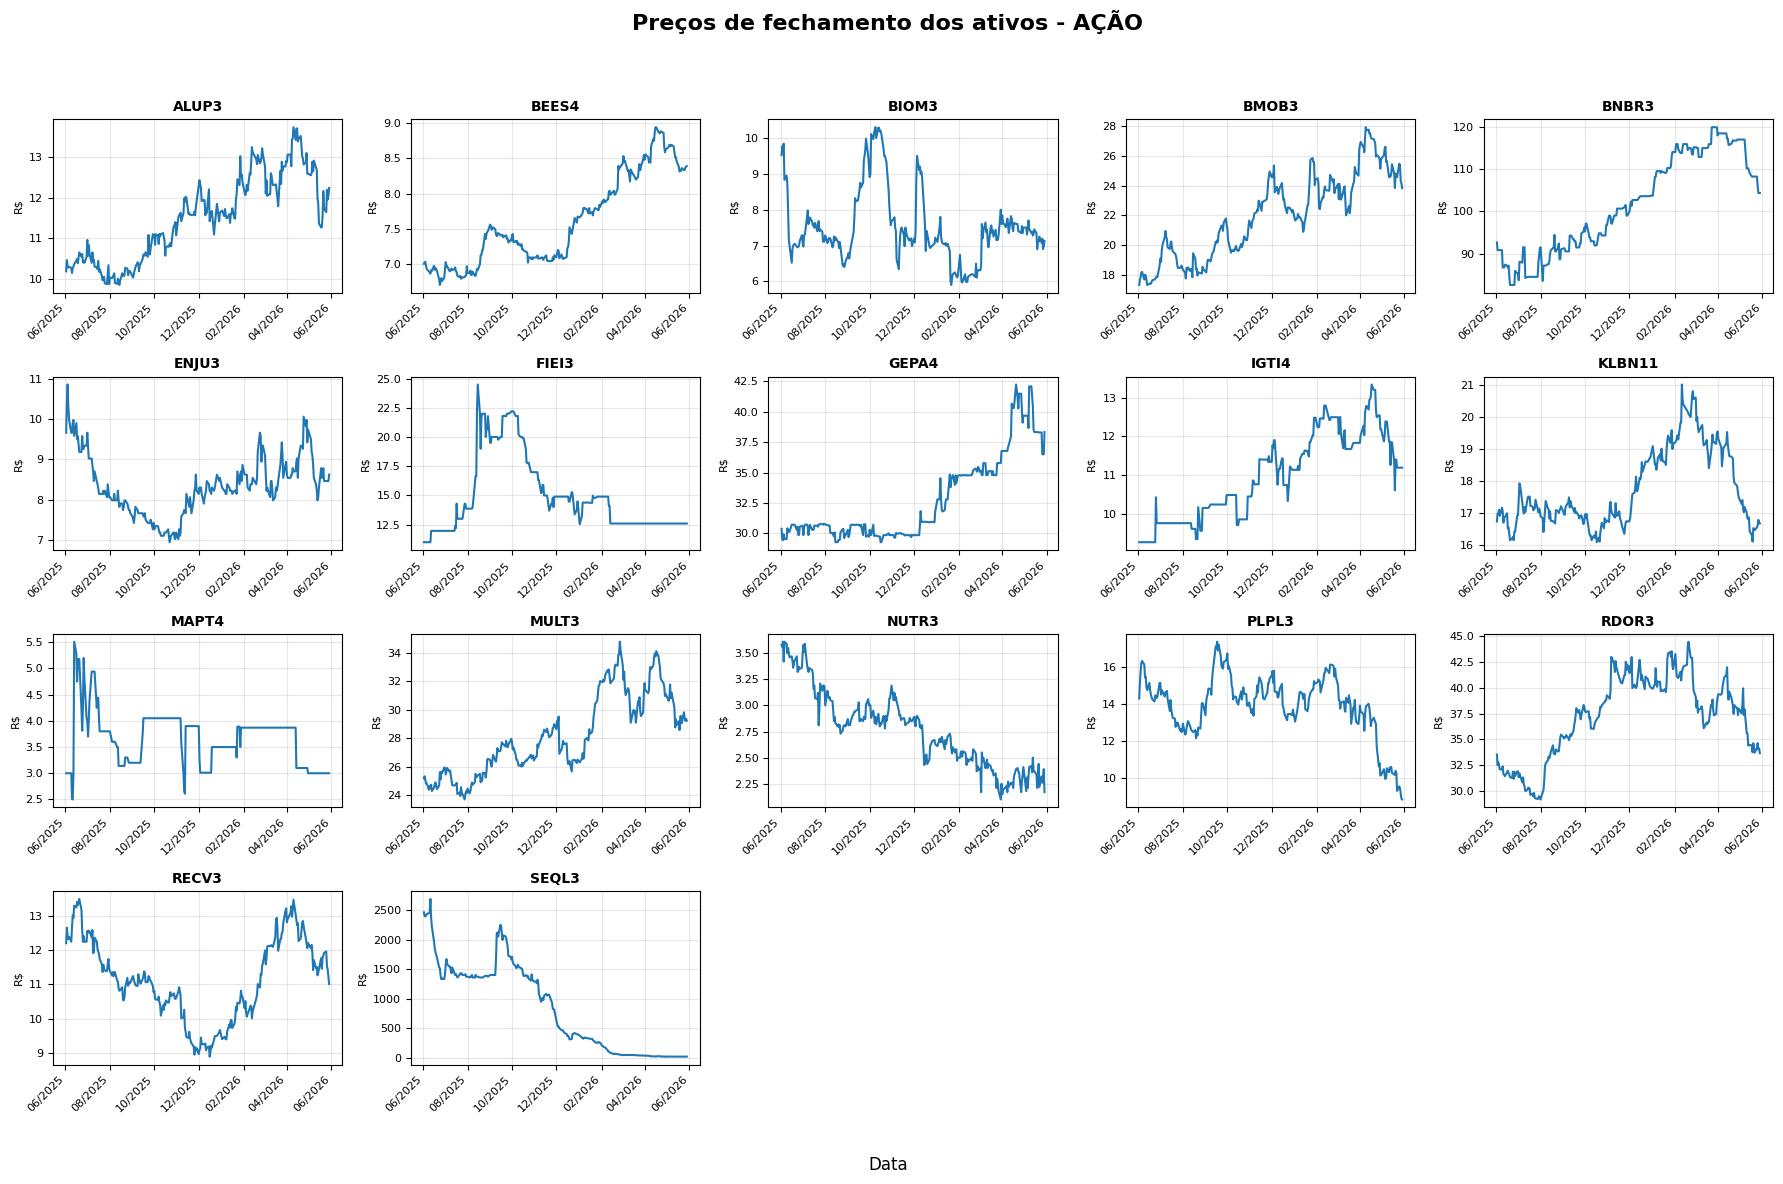

[****************************132%*******************************]  1028 of 776 completed

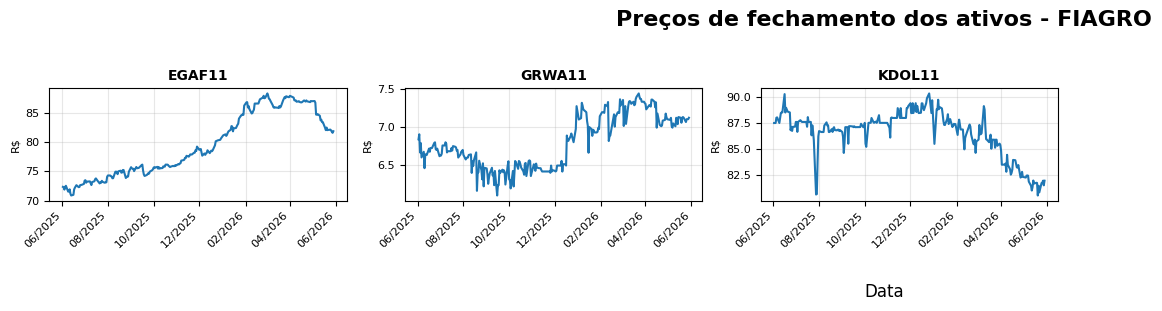

[*******************************142%*********************************]  1104 of 776 completed

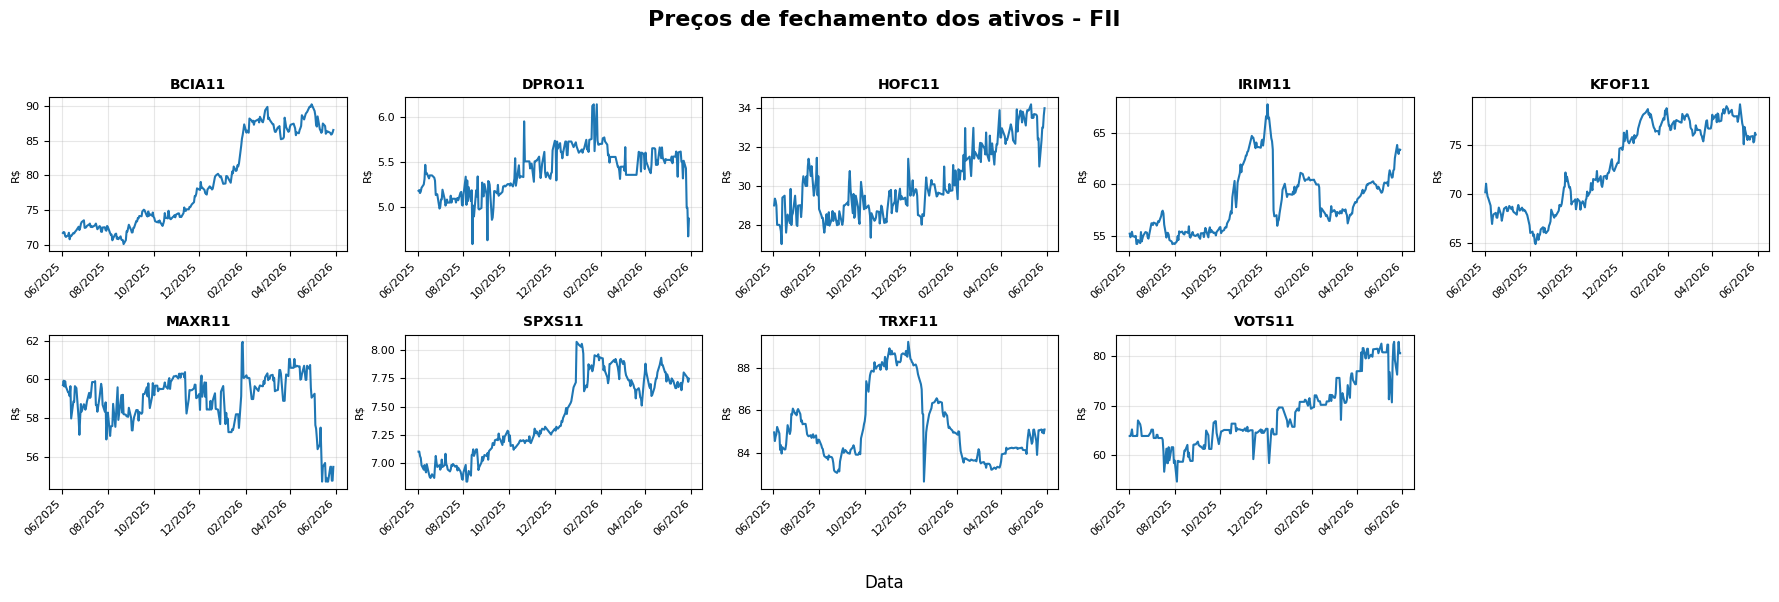

In [13]:
# Garantir que o índice seja datetime
close_data.index = pd.to_datetime(close_data.index)

# Associar cada ticker ao seu tipo de ativo
tipos_ativos = ativos_validos_df[
    ["ticker_yahoo", "tipo"]
].drop_duplicates()

# Separar os tickers por tipo
tickers_por_tipo = {
    tipo: grupo["ticker_yahoo"].tolist()
    for tipo, grupo in tipos_ativos.groupby("tipo")
}

# Configurações padronizadas
ncols = 5
titulo_fontsize = 16
titulo_y = 0.98

# Caminho para salvar as imagens
pasta = r"C:\Users\tania valasky\OneDrive - ufpr.br\Área de Trabalho\Arquivos - TCC"

# Gerar um gráfico para cada tipo de ativo
for tipo, tickers in tickers_por_tipo.items():

    # Selecionar somente os ativos presentes em close_data
    tickers = [
        ticker for ticker in tickers
        if ticker in close_data.columns
    ]

    n_ativos = len(tickers)

    if n_ativos == 0:
        continue

    # Definir quantidade de linhas
    nrows = math.ceil(n_ativos / ncols)

    # Criar figura
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(18, 3 * nrows),
        sharex=True
    )

    # Transformar os eixos em uma lista
    axes = axes.flatten() if n_ativos > 1 else [axes]

    # Plotar cada ativo
    for i, ativo in enumerate(tickers):

        axes[i].plot(
            close_data.index,
            close_data[ativo],
            linewidth=1.5
        )

        axes[i].set_title(
            ativo.replace(".SA", ""),
            fontsize=10,
            fontweight="bold"
        )

        axes[i].set_ylabel("R$", fontsize=8)

        axes[i].grid(True, alpha=0.3)

        axes[i].tick_params(
            axis="both",
            labelsize=8,
            labelbottom=True
        )

        # Formatação das datas em todos os painéis
        axes[i].xaxis.set_major_locator(
            mdates.MonthLocator(interval=2)
        )

        axes[i].xaxis.set_major_formatter(
            mdates.DateFormatter("%m/%Y")
        )

        plt.setp(
            axes[i].get_xticklabels(),
            rotation=45,
            ha="right"
        )

    # Ocultar painéis vazios
    for j in range(n_ativos, len(axes)):
        axes[j].set_visible(False)

    # Título geral padronizado
    fig.suptitle(
        f"Preços de fechamento dos ativos - {tipo}",
        fontsize=titulo_fontsize,
        fontweight="bold",
        y=titulo_y
    )

    # Nome do eixo X
    fig.supxlabel("Data", fontsize=12)

    # Ajustar espaçamento
    plt.tight_layout(
        rect=[0, 0.02, 1, 0.95]
    )

    # Caminho para salvar
    caminho = rf"{pasta}\precos_{tipo.lower()}.png"

    # Salvar figura
    fig.savefig(
        caminho,
        dpi=300
    )

    plt.show()

    plt.close(fig)

## Cálculo de Retornos

In [14]:
# Cálculo de Retornos, Covariância, etc.

# Retornos diários
retornos = (close_data.values[1:] - close_data.values[:-1]) / close_data.values[:-1]

# Covariância dos retornos diários
Q_diario = np.cov(retornos.T)

# Retornos médios diários
v_diario = np.mean(retornos, axis=0)

# Conversão para base ANUAL
DIAS_UTEIS_ANO = 252

v = (1 + v_diario)**DIAS_UTEIS_ANO - 1                         # retorno anualizado
Q = Q_diario * DIAS_UTEIS_ANO                                   # covariância anualizada
risco_todos = np.std(retornos, axis=0) * np.sqrt(DIAS_UTEIS_ANO) # risco (volatilidade) anualizada

print("Retorno anualizado (v):",v)
print("\nCovariância anualizada (Q):", Q)
print("\nRisco anualizado (risco_todos):", risco_todos)


Retorno anualizado (v): [ 0.27256692  0.21858787  0.21134959 -0.09439182  0.4658474   0.16132601
  0.04734103  0.13723202 -0.03409913  0.38901385  0.30862953  0.08374505
  0.27996218  0.16946353 -0.05248882  0.09443871  0.01916811  0.84550084
 -0.05865395  0.20547086 -0.31289494 -0.31453674  0.05060987 -0.05775491
 -0.98846655  0.10120281  0.00409779  0.40066835  0.27385596]

Covariância anualizada (Q): [[ 1.07547643e-01  1.15951307e-03  2.08493360e-03  1.05791252e-02
   3.23300249e-02  1.54524000e-03 -1.26143400e-02 -5.30309125e-04
   2.72185412e-02 -2.11015821e-02  1.22644301e-02  8.07629326e-03
   2.17899149e-02  8.09596067e-03 -3.33209414e-03  7.99316471e-03
   1.47402294e-02  1.31991719e-03 -2.95358004e-03  3.91912234e-02
   3.72866850e-03  5.08278979e-02  3.33720602e-02  1.81583300e-02
  -2.34573403e-03  5.22908658e-03 -6.12091105e-04 -1.21367742e-02
  -6.55725710e-03]
 [ 1.15951307e-03  1.40753479e-02 -3.53225938e-05 -2.17021030e-03
   3.49195053e-03  3.12636363e-03  6.03556898e

[*******************************143%**********************************]  1107 of 776 completed

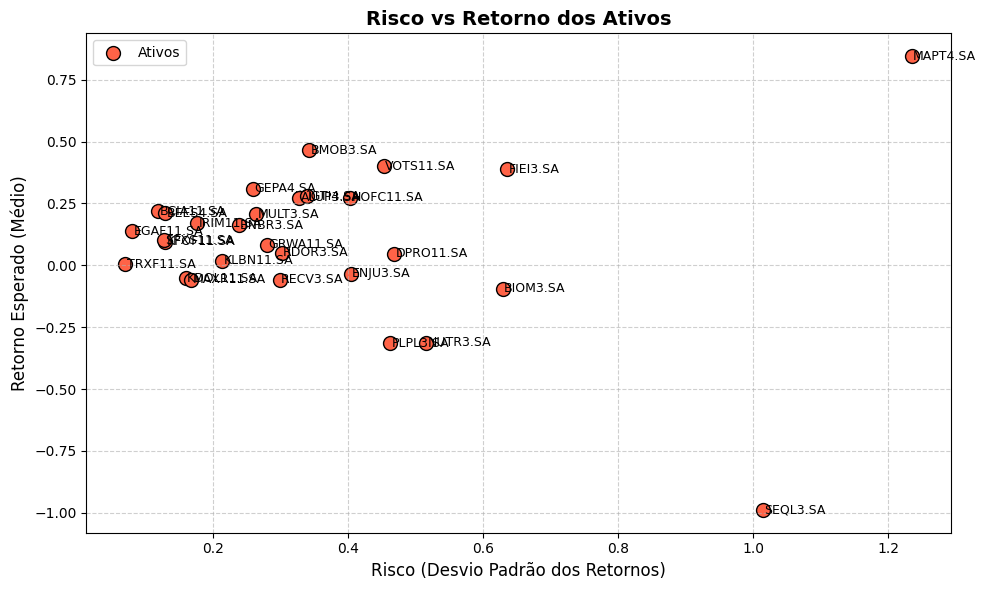

In [15]:
# PLOT Risco x Retorno

plt.figure(figsize=(10, 6))

# Pontos dos ativos
plt.scatter(risco_todos, v, color='tomato', edgecolor='black', s=100, label='Ativos')

# Adiciona o nome de cada ativo
for i, ativo in enumerate(close_data.columns):
    plt.text(risco_todos[i] + 0.002, v[i], ativo, fontsize=9, color='black', ha='left', va='center')

# Título e eixos
plt.title("Risco vs Retorno dos Ativos", fontsize=14, weight='bold')
plt.xlabel("Risco (Desvio Padrão dos Retornos)", fontsize=12)
plt.ylabel("Retorno Esperado (Médio)", fontsize=12)

# Grade e legenda
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

In [16]:
# 1. Criar DataFrame com risco e retorno

risco_retorno = pd.DataFrame({
    "ticker_yahoo": close_data.columns,
    "risco": risco_todos,
    "retorno": v
})

# 2. Adicionar o tipo do ativo (AÇÃO ou FII)

risco_retorno = risco_retorno.merge(
    ativos_validos_df[["ticker_yahoo", "tipo"]],
    on="ticker_yahoo",
    how="left"
)

risco_retorno

,ticker_yahoo,risco,retorno,tipo
0,ALUP3.SA,0.327283,0.272567,AÇÃO
1,BCIA11.SA,0.118400,0.218588,FII
2,BEES4.SA,0.128876,0.211350,AÇÃO
3,BIOM3.SA,0.628306,-0.094392,AÇÃO
4,BMOB3.SA,0.341759,0.465847,AÇÃO
5,BNBR3.SA,0.237610,0.161326,AÇÃO
6,DPRO11.SA,0.467844,0.047341,FII
7,EGAF11.SA,0.079429,0.137232,FIAGRO
8,ENJU3.SA,0.403190,-0.034099,AÇÃO
9,FIEI3.SA,0.635437,0.389014,AÇÃO


[*********************************149%***********************************]  1153 of 776 completed

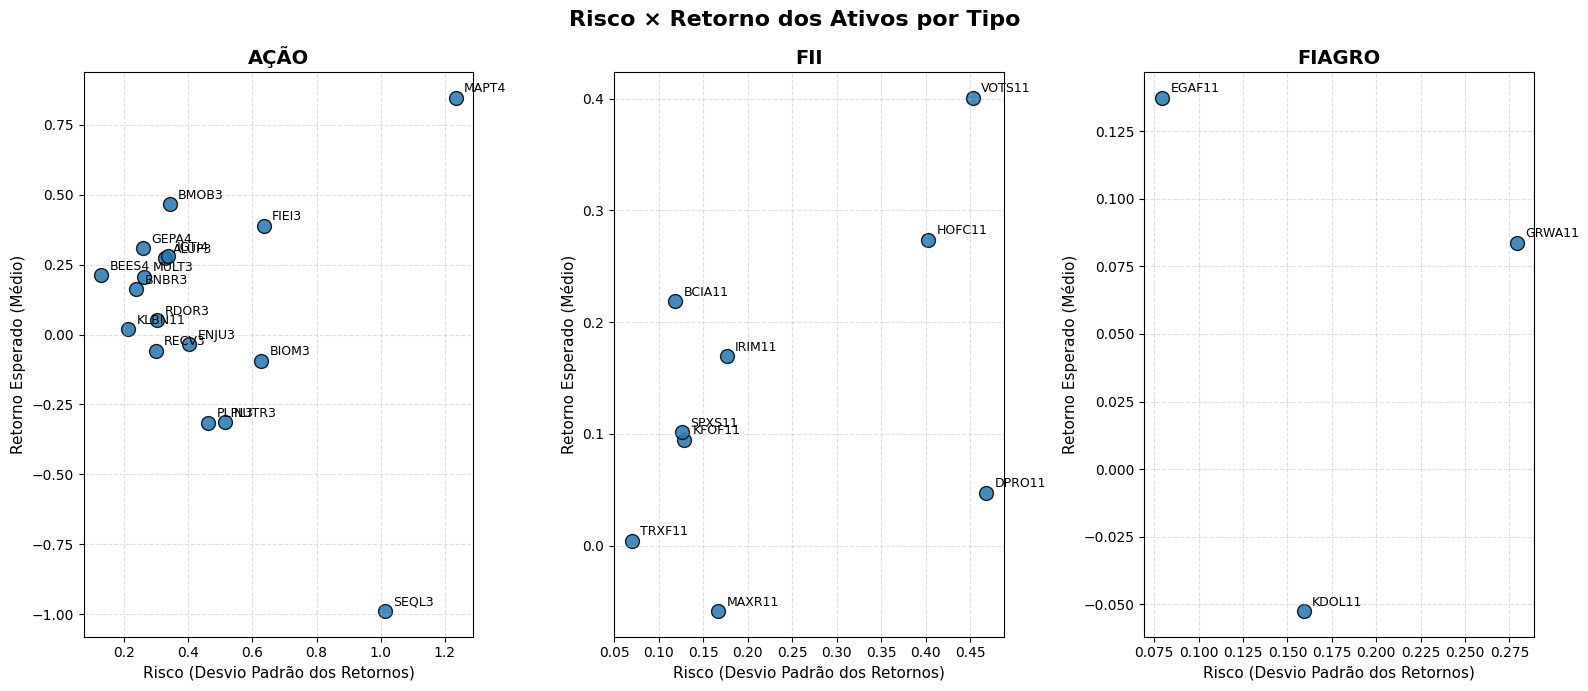

In [17]:
# ============================================================
# PLOT RISCO x RETORNO POR TIPO DE ATIVO
# ============================================================

tipos = risco_retorno["tipo"].dropna().unique()

fig, axes = plt.subplots(1, len(tipos), figsize=(16, 7), squeeze=False)
axes = axes.flatten()

for ax, tipo in zip(axes, tipos):
    # Filtrar o tipo atual
    dados_tipo = risco_retorno[risco_retorno["tipo"] == tipo].copy()

    # Plotar os pontos
    ax.scatter(dados_tipo["risco"], dados_tipo["retorno"], s=100, edgecolor="black", alpha=0.85)

    # Adicionar nome de cada ativo
    for _, linha in dados_tipo.iterrows():
        ax.annotate(linha["ticker_yahoo"].replace(".SA", ""), xy=(linha["risco"], linha["retorno"]), xytext=(6, 4), textcoords="offset points", fontsize=9)

    # Título
    ax.set_title(f"{tipo}", fontsize=14, fontweight="bold")

    # Eixos
    ax.set_xlabel("Risco (Desvio Padrão dos Retornos)", fontsize=11)
    ax.set_ylabel("Retorno Esperado (Médio)", fontsize=11)

    # Grade
    ax.grid(True, linestyle="--", alpha=0.4)

# Título geral
fig.suptitle("Risco × Retorno dos Ativos por Tipo", fontsize=16, fontweight="bold")

plt.tight_layout()

# Caminho onde a imagem será salva
caminho = r"C:\Users\tania valasky\OneDrive - ufpr.br\Área de Trabalho\Arquivos - TCC\risco_retorno_30_ativos.png"

# Salvar a figura
fig.savefig(caminho, dpi=300, bbox_inches="tight")

plt.show()

In [18]:
# Verifica NaN e Inf

print("Q contém NaN? ", np.isnan(Q).any())
print("Q contém Inf? ", np.isinf(Q).any())

print("v contém NaN? ", np.isnan(v).any())
print("v contém Inf? ", np.isinf(v).any())

Q contém NaN?  False
Q contém Inf?  False
v contém NaN?  False
v contém Inf?  False


## Modelo

In [22]:
# Q: matriz de covariância (n x n)
# v: vetor de retornos médios (n,)
# rho: retorno mínimo exigido

n = len(v)   # número de ativos
rho = 0.1   # retorno mínimo (altere para o valor desejado)
alpha = 15    # número máximo de ativos (altere para o valor desejado)

model = gp.Model("Modelo Exato")

# Variáveis
x = model.addMVar(n, vtype=GRB.CONTINUOUS, name="x")
y = model.addMVar(n, lb=0, ub=1, vtype=GRB.BINARY, name="y")

# Função objetivo (minimizar risco)
obj = x @ Q @ x
model.setObjective(obj, GRB.MINIMIZE)

# Restrições
model.addConstr(v @ x >= rho, "retorno_minimo")    # retorno mínimo
model.addConstr(x.sum() == 1, "vetor de uns")   # soma dos pesos = 1
model.addConstr(x <= y, "link_x_y")  # se y_i = 0, então x_i = 0
model.addConstr(y.sum() <= alpha, "somatorio")  # a soma dos ativos escolhidos não pode ultrapassar a quantidade maxima de ativos

# Otimização
model.optimize()


# Verificar solução
if model.status == GRB.OPTIMAL:

    # Extrair pesos e ativos selecionados
    pesos = x.X
    selecionados = np.where(y.X > 0.5)[0]

    for i in selecionados:
        print(
            f"Ativo {ativos_select[i]}: "
            f"peso = {pesos[i]:.4f}, "
            f"selecionado (y={y.X[i]:.0f})"
        )

else:
    print("Solução ótima não encontrada.")

Restricted license - for non-production use only - expires 2028-11-29
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 32 rows, 58 columns and 145 nonzeros (Min)
Model fingerprint: 0xdb636c3a
Model has 0 linear objective coefficients
Model has 435 quadratic objective terms
Variable types: 29 continuous, 29 integer (29 binary)
Coefficient statistics:
  Matrix range     [4e-03, 1e+00]
  Objective range  [0e+00, 0e+00]
  QObjective range [7e-05, 3e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e-01, 2e+01]

Found heuristic solution: objective 0.4314641
Presolve time: 0.00s
Presolved: 44 rows, 64 columns, 168 nonzeros
Presolved model has 441 quadratic objective terms
Variable types: 35 continuous, 29 integer (29 binary)

Root relaxation: objective 1.797157e-03, 90 iteratio

# Risco e Retorno da Carteira

In [23]:
risco = np.sqrt(x.X @ Q @ x.X)  # x.X é o vetor de pesos ótimo retornado pelo Gurobi
retorno = v @ x.X

print(f"O risco da carteira é: {risco:.4f}")
print(f"O retorno da carteira é: {retorno:.4f}")

O risco da carteira é: 0.0426
O retorno da carteira é: 0.1000


In [24]:
# ------------------- MÉTRICAS DA CARTEIRA -------------------

# Retorno esperado da carteira
retorno_carteira = float(v @ pesos)

# Variância da carteira
variancia_carteira = float(pesos @ Q @ pesos)

# Risco da carteira (desvio padrão)
risco_carteira = np.sqrt(variancia_carteira)

print("\n--- MÉTRICAS DA CARTEIRA OTIMIZADA ---")
print(f"Rentabilidade esperada: {retorno_carteira * 100:.2f}%")
print(f"Risco da carteira: {risco_carteira * 100:.2f}%")


--- MÉTRICAS DA CARTEIRA OTIMIZADA ---
Rentabilidade esperada: 10.00%
Risco da carteira: 4.26%


## Conferência dos Exemplos

**Exemplo 1:**

In [30]:
# conferencia exemplo 1


import numpy as np
import pandas as pd

# ============================================================
# 1. PARÂMETROS DO PROBLEMA
# ============================================================

valor_disponivel = 1000.00
rho = 0.12
alpha = 15
tolerancia = 1e-6

# ============================================================
# 2. CARTEIRA RETORNADA PELO APLICATIVO
# ============================================================

carteira_app = pd.DataFrame({
    "ativo": [
        "ALUP3.SA", "BEES4.SA", "GEPA4.SA",
        "EGAF11.SA", "GRWA11.SA", "BCIA11.SA",
        "DPRO11.SA", "SPXS11.SA", "TRXF11.SA"
    ],
    "quantidade": [2, 17, 1, 3, 2, 1, 2, 11, 4],
    "valor": [
        24.63, 143.08, 38.33,
        249.41, 14.44, 87.44,
        9.84, 86.45, 345.21
    ]
})

# ============================================================
# 3. ORGANIZAR OS DADOS DO MODELO
# ============================================================

ativos_modelo = list(close_data.columns)

# Verificar se os dados possuem dimensões compatíveis
assert len(v) == len(ativos_modelo), "Dimensão de v incompatível."
assert Q.shape == (len(v), len(v)), "Dimensão de Q incompatível."

# Verificar se todos os ativos estão na base
nao_encontrados = set(carteira_app["ativo"]) - set(ativos_modelo)

if nao_encontrados:
    raise ValueError(f"Ativos não encontrados na base: {nao_encontrados}")

# Criar vetor de pesos com todos os ativos da base.
# Os ativos que não estão na carteira recebem peso zero.

valores = carteira_app.set_index("ativo")["valor"]

x = np.array([
    valores.get(ativo, 0.0) / valor_disponivel
    for ativo in ativos_modelo
])

# Variáveis binárias: 1 para ativos comprados e 0 para os demais
y = np.array([
    1 if ativo in valores.index else 0
    for ativo in ativos_modelo
])

# ============================================================
# 4. CALCULAR RETORNO E RISCO
# ============================================================

retorno_carteira = float(v @ x)

variancia_carteira = float(x @ Q @ x)

risco_carteira = np.sqrt(max(variancia_carteira, 0))

valor_investido = carteira_app["valor"].sum()
soma_pesos = x.sum()
saldo = valor_disponivel - valor_investido

# ============================================================
# 5. VERIFICAR AS RESTRIÇÕES
# ============================================================

restricoes = {
    "Retorno mínimo (v.T @ x >= rho)":
        retorno_carteira >= rho - tolerancia,

    "Capital investido (soma dos pesos = 1)":
        abs(soma_pesos - 1) <= tolerancia,

    "Não negatividade (x >= 0)":
        np.all(x >= -tolerancia),

    "Ligação entre x e y (x <= y)":
        np.all(x <= y + tolerancia),

    "Cardinalidade (soma de y <= alpha)":
        y.sum() <= alpha,

    "Variáveis binárias (y em {0,1})":
        np.all(np.isin(y, [0, 1]))
}

# ============================================================
# 6. EXIBIR RESULTADOS
# ============================================================

print("=" * 65)
print("VALIDAÇÃO DA CARTEIRA - EXEMPLO 1")
print("=" * 65)

print(f"\nValor disponível:       R$ {valor_disponivel:.2f}")
print(f"Valor efetivamente investido: R$ {valor_investido:.2f}")
print(f"Saldo não investido:    R$ {saldo:.2f}")
print(f"Número de ativos:       {int(y.sum())}")
print(f"Soma dos pesos:         {soma_pesos:.6f}")

print("\n--- MÉTRICAS DA CARTEIRA ---")

print(f"Retorno mínimo exigido: {rho * 100:.2f}%")
print(f"Retorno calculado:      {retorno_carteira * 100:.2f}%")
print(f"Risco calculado:        {risco_carteira * 100:.2f}%")

print("\n--- VERIFICAÇÃO DAS RESTRIÇÕES ---")

for nome, resultado in restricoes.items():
    situacao = "SATISFEITA" if resultado else "NÃO SATISFEITA"
    print(f"{nome}: {situacao}")

# ============================================================
# 7. EXIBIR PESOS EFETIVOS
# ============================================================

resultado = carteira_app.copy()

resultado["peso (%)"] = (
    resultado["valor"] / valor_disponivel * 100
)

print("\n--- COMPOSIÇÃO DA CARTEIRA ---")
print(resultado.to_string(index=False))

print("\n" + "=" * 65)

if all(restricoes.values()):
    print("A carteira satisfaz todas as restrições.")
else:
    print("A carteira NÃO satisfaz todas as restrições.")


VALIDAÇÃO DA CARTEIRA - EXEMPLO 1

Valor disponível:       R$ 1000.00
Valor efetivamente investido: R$ 998.83
Saldo não investido:    R$ 1.17
Número de ativos:       9
Soma dos pesos:         0.998830

--- MÉTRICAS DA CARTEIRA ---
Retorno mínimo exigido: 12.00%
Retorno calculado:      11.40%
Risco calculado:        4.62%

--- VERIFICAÇÃO DAS RESTRIÇÕES ---
Retorno mínimo (v.T @ x >= rho): NÃO SATISFEITA
Capital investido (soma dos pesos = 1): NÃO SATISFEITA
Não negatividade (x >= 0): SATISFEITA
Ligação entre x e y (x <= y): SATISFEITA
Cardinalidade (soma de y <= alpha): SATISFEITA
Variáveis binárias (y em {0,1}): SATISFEITA

--- COMPOSIÇÃO DA CARTEIRA ---
    ativo  quantidade  valor  peso (%)
 ALUP3.SA           2  24.63     2.463
 BEES4.SA          17 143.08    14.308
 GEPA4.SA           1  38.33     3.833
EGAF11.SA           3 249.41    24.941
GRWA11.SA           2  14.44     1.444
BCIA11.SA           1  87.44     8.744
DPRO11.SA           2   9.84     0.984
SPXS11.SA          11  8

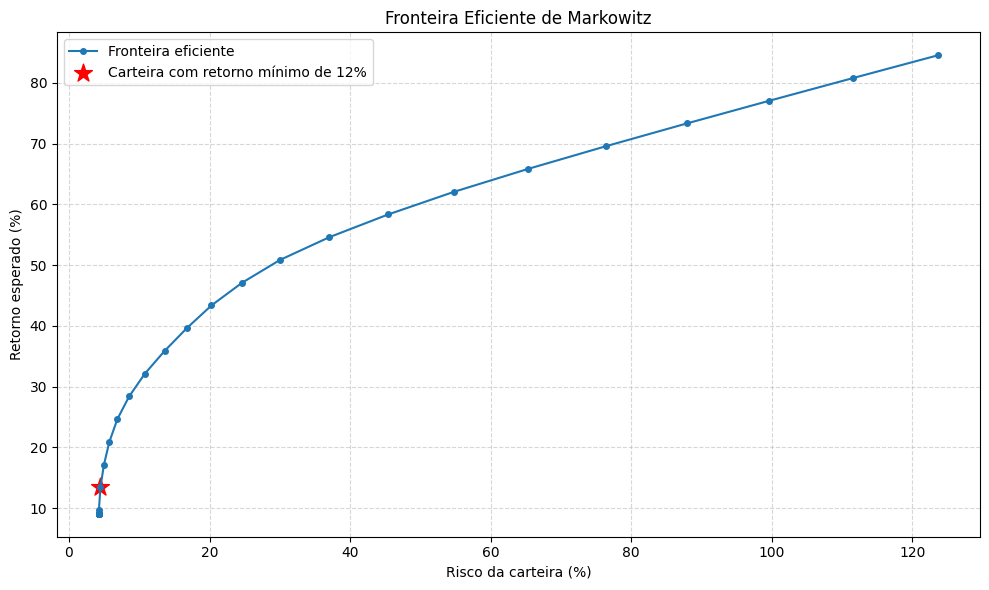

In [31]:
# Fronteira Eficiente

import gurobipy as gp
from gurobipy import GRB
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros
n = len(v)
alpha = 15

# Variação dos retornos mínimos exigidos
retornos_alvo = np.linspace(np.min(v), np.max(v), 50)

riscos = []
retornos = []

for rho in retornos_alvo:

    modelo = gp.Model("Fronteira_Eficiente")
    modelo.setParam("OutputFlag", 0)

    # Variáveis de decisão
    x = modelo.addVars(n, lb=0, vtype=GRB.CONTINUOUS, name="x")
    y = modelo.addVars(n, vtype=GRB.BINARY, name="y")

    # Função objetivo: minimizar a variância
    modelo.setObjective(
        gp.quicksum(
            Q[i, j] * x[i] * x[j]
            for i in range(n)
            for j in range(n)
        ),
        GRB.MINIMIZE
    )

    # Restrições
    modelo.addConstr(gp.quicksum(x[i] for i in range(n)) == 1)
    modelo.addConstrs(x[i] <= y[i] for i in range(n))
    modelo.addConstr(gp.quicksum(y[i] for i in range(n)) <= alpha)

    modelo.addConstr(
        gp.quicksum(v[i] * x[i] for i in range(n)) >= rho
    )

    # Otimização
    modelo.optimize()

    # Armazenar resultados das soluções viáveis
    if modelo.Status == GRB.OPTIMAL:

        pesos = np.array([x[i].X for i in range(n)])

        retorno = np.dot(v, pesos)
        variancia = pesos @ Q @ pesos
        risco = np.sqrt(variancia)

        retornos.append(retorno * 100)
        riscos.append(risco * 100)


# Identificar a carteira com retorno mínimo de 12%
rho_destaque = 12.0

# Identificar a carteira com retorno mínimo de 20%
#rho_destaque = 20.0

indice = np.argmin(
    np.abs(np.array(retornos) - rho_destaque)
)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    riscos,
    retornos,
    marker='o',
    markersize=4,
    linestyle='-',
    label='Fronteira eficiente'
)

plt.scatter(
    riscos[indice],
    retornos[indice],
    color='red',
    marker='*',
    s=180,
    label='Carteira com retorno mínimo de 12%'
)

plt.xlabel('Risco da carteira (%)')
plt.ylabel('Retorno esperado (%)')
plt.title('Fronteira Eficiente de Markowitz')

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

# Caminho onde a imagem será salva
#caminho = r"C:\Users\tania valasky\OneDrive - ufpr.br\Área de Trabalho\Arquivos - TCC\fronteira_eficiente_retorno20.png"
# Salvar a figura
#plt.savefig(caminho, dpi=300, bbox_inches="tight")

plt.show()

In [32]:
# Verificação desconsiderando o valor disponivel, olhando só para os pesos (saída do modelo) - exemplo 1

# ============================================================
# 1. PARÂMETROS
# ============================================================

rho = 0.12
alpha = 15
tolerancia = 1e-6

ativos = list(close_data.columns)
n = len(ativos)

# ============================================================
# 2. MODELO DE OTIMIZAÇÃO
# ============================================================

model = gp.Model("Validacao_Pesos")
model.Params.LogToConsole = 0

x = model.addMVar(
    n, vtype=GRB.CONTINUOUS, name="x"
)

y = model.addMVar(
    n, lb=0, ub=1, vtype=GRB.BINARY, name="y"
)

# Função objetivo: minimizar risco
model.setObjective(x @ Q @ x, GRB.MINIMIZE)

# Restrições
model.addConstr(v @ x >= rho, "retorno_minimo")
model.addConstr(x.sum() == 1, "soma_pesos")
model.addConstr(x <= y, "ligacao_x_y")
model.addConstr(y.sum() <= alpha, "cardinalidade")

# Executar otimização
model.optimize()

# ============================================================
# 3. EXTRAIR SOLUÇÃO
# ============================================================

if model.status == GRB.OPTIMAL:

    pesos = x.X
    binarias = y.X

    # Identificar ativos selecionados
    selecionados = np.where(
        (binarias > 0.5) & (pesos > tolerancia)
    )[0]

    ativos_selecionados = [
        ativos[i] for i in selecionados
    ]

    pesos_selecionados = pesos[selecionados]

    # ========================================================
    # 4. APRESENTAR CARTEIRA OTIMIZADA
    # ========================================================

    carteira = pd.DataFrame({
        "Ativo": ativos_selecionados,
        "Peso": pesos_selecionados,
        "Peso (%)": pesos_selecionados * 100
    })

    carteira = carteira.sort_values(
        "Peso (%)", ascending=False
    ).reset_index(drop=True)

    print("=" * 65)
    print("CARTEIRA OTIMIZADA - Gurobi")
    print("=" * 65)

    print(carteira.to_string(index=False))

    # ========================================================
    # 5. CALCULAR RETORNO E RISCO
    # ========================================================

    retorno = float(v @ pesos)
    variancia = float(pesos @ Q @ pesos)
    risco = np.sqrt(max(variancia, 0))

    print("\n--- MÉTRICAS DA CARTEIRA ---")

    print(f"Retorno mínimo exigido: {rho * 100:.2f}%")
    print(f"Retorno obtido:         {retorno * 100:.2f}%")
    print(f"Risco da carteira:      {risco * 100:.2f}%")
    print(f"Variância:              {variancia:.8f}")
    print(f"Soma dos pesos:         {pesos.sum():.8f}")
    print(f"Quantidade de ativos:   {len(selecionados)}")

    # ========================================================
    # 6. VERIFICAR RESTRIÇÕES
    # ========================================================

    restricoes = {
        "Retorno mínimo (v.T @ x >= rho)":
            retorno >= rho - tolerancia,

        "Soma dos pesos (soma de x = 1)":
            abs(pesos.sum() - 1) <= tolerancia,

        "Não negatividade (x >= 0)":
            np.all(pesos >= -tolerancia),

        "Ligação entre x e y (x <= y)":
            np.all(pesos <= binarias + tolerancia),

        "Cardinalidade (soma de y <= alpha)":
            binarias.sum() <= alpha + tolerancia,

        "Variáveis binárias (y em {0,1})":
            np.all(
                (np.abs(binarias) <= tolerancia) |
                (np.abs(binarias - 1) <= tolerancia)
            )
    }

    print("\n--- VERIFICAÇÃO DAS RESTRIÇÕES ---")

    for nome, resultado in restricoes.items():
        situacao = (
            "SATISFEITA" if resultado
            else "NÃO SATISFEITA"
        )
        print(f"{nome}: {situacao}")

    print("\n" + "=" * 65)

    if all(restricoes.values()):
        print("Todas as restrições foram satisfeitas.")
    else:
        print("Existem restrições não satisfeitas.")

else:
    print("Solução ótima não encontrada.")
    print("Status do Gurobi:", model.status)


CARTEIRA OTIMIZADA - Gurobi
    Ativo     Peso  Peso (%)
TRXF11.SA 0.273562 27.356234
EGAF11.SA 0.232052 23.205165
 BEES4.SA 0.138211 13.821124
BCIA11.SA 0.093889  9.388930
SPXS11.SA 0.079832  7.983165
KDOL11.SA 0.044539  4.453941
IRIM11.SA 0.037795  3.779481
VOTS11.SA 0.023755  2.375502
 ALUP3.SA 0.017591  1.759077
 GEPA4.SA 0.015006  1.500650
GRWA11.SA 0.012166  1.216646
HOFC11.SA 0.011466  1.146587
DPRO11.SA 0.007737  0.773713
 BIOM3.SA 0.006492  0.649179
 FIEI3.SA 0.005906  0.590606

--- MÉTRICAS DA CARTEIRA ---
Retorno mínimo exigido: 12.00%
Retorno obtido:         12.00%
Risco da carteira:      4.35%
Variância:              0.00189363
Soma dos pesos:         1.00000000
Quantidade de ativos:   15

--- VERIFICAÇÃO DAS RESTRIÇÕES ---
Retorno mínimo (v.T @ x >= rho): SATISFEITA
Soma dos pesos (soma de x = 1): SATISFEITA
Não negatividade (x >= 0): SATISFEITA
Ligação entre x e y (x <= y): SATISFEITA
Cardinalidade (soma de y <= alpha): SATISFEITA
Variáveis binárias (y em {0,1}): SATISFE

**Exemplo 2:**

In [33]:
# verificação do exemplo 2 considerando a carteira do aplicativo

# ============================================================
# 1. PARÂMETROS DO PROBLEMA
# ============================================================

valor_disponivel = 1000.00
rho = 0.20
alpha = 15
tolerancia = 1e-6

# ============================================================
# 2. CARTEIRA RETORNADA PELO APLICATIVO
# ============================================================

carteira_app = pd.DataFrame({
    "ativo": [
        "ALUP3.SA", "BEES4.SA", "BMOB3.SA",
        "GEPA4.SA", "IGTI4.SA", "MAPT4.SA",
        "EGAF11.SA", "BCIA11.SA", "IRIM11.SA",
        "SPXS11.SA", "TRXF11.SA"
    ],
    "quantidade": [1, 22, 1, 1, 1, 2, 4, 2, 1, 8, 1],
    "valor": [
        12.31, 185.16, 23.83,
        38.33, 11.20, 6.00,
        332.54, 174.89, 64.20,
        62.87, 86.30
    ]
})

# ============================================================
# 3. ORGANIZAR OS DADOS DO MODELO
# ============================================================

ativos_modelo = list(close_data.columns)

# Verificar se os dados possuem dimensões compatíveis
assert len(v) == len(ativos_modelo), "Dimensão de v incompatível."
assert Q.shape == (len(v), len(v)), "Dimensão de Q incompatível."

# Verificar se todos os ativos estão na base
nao_encontrados = set(carteira_app["ativo"]) - set(ativos_modelo)

if nao_encontrados:
    raise ValueError(f"Ativos não encontrados na base: {nao_encontrados}")

# Criar vetor de pesos com todos os ativos da base.
# Os ativos que não estão na carteira recebem peso zero.

valores = carteira_app.set_index("ativo")["valor"]

x = np.array([
    valores.get(ativo, 0.0) / valor_disponivel
    for ativo in ativos_modelo
])

# Variáveis binárias: 1 para ativos comprados e 0 para os demais
y = np.array([
    1 if ativo in valores.index else 0
    for ativo in ativos_modelo
])

# ============================================================
# 4. CALCULAR RETORNO E RISCO
# ============================================================

retorno_carteira = float(v @ x)

variancia_carteira = float(x @ Q @ x)

risco_carteira = np.sqrt(max(variancia_carteira, 0))

valor_investido = carteira_app["valor"].sum()
soma_pesos = x.sum()
saldo = valor_disponivel - valor_investido

# ============================================================
# 5. VERIFICAR AS RESTRIÇÕES
# ============================================================

restricoes = {
    "Retorno mínimo (v.T @ x >= rho)":
        retorno_carteira >= rho - tolerancia,

    "Capital investido (soma dos pesos = 1)":
        abs(soma_pesos - 1) <= tolerancia,

    "Não negatividade (x >= 0)":
        np.all(x >= -tolerancia),

    "Ligação entre x e y (x <= y)":
        np.all(x <= y + tolerancia),

    "Cardinalidade (soma de y <= alpha)":
        y.sum() <= alpha,

    "Variáveis binárias (y em {0,1})":
        np.all(np.isin(y, [0, 1]))
}

# ============================================================
# 6. EXIBIR RESULTADOS
# ============================================================

print("=" * 65)
print("VALIDAÇÃO DA CARTEIRA - EXEMPLO 2")
print("=" * 65)

print(f"\nValor disponível:       R$ {valor_disponivel:.2f}")
print(f"Valor efetivamente investido: R$ {valor_investido:.2f}")
print(f"Saldo não investido:    R$ {saldo:.2f}")
print(f"Número de ativos:       {int(y.sum())}")
print(f"Soma dos pesos:         {soma_pesos:.6f}")

print("\n--- MÉTRICAS DA CARTEIRA ---")

print(f"Retorno mínimo exigido: {rho * 100:.2f}%")
print(f"Retorno calculado:      {retorno_carteira * 100:.2f}%")
print(f"Risco calculado:        {risco_carteira * 100:.2f}%")

print("\n--- VERIFICAÇÃO DAS RESTRIÇÕES ---")

for nome, resultado in restricoes.items():
    situacao = "SATISFEITA" if resultado else "NÃO SATISFEITA"
    print(f"{nome}: {situacao}")

# ============================================================
# 7. EXIBIR PESOS EFETIVOS
# ============================================================

resultado = carteira_app.copy()

resultado["peso (%)"] = (
    resultado["valor"] / valor_disponivel * 100
)

print("\n--- COMPOSIÇÃO DA CARTEIRA ---")
print(resultado.to_string(index=False))

print("\n" + "=" * 65)

if all(restricoes.values()):
    print("A carteira satisfaz todas as restrições.")
else:
    print("A carteira NÃO satisfaz todas as restrições.")


VALIDAÇÃO DA CARTEIRA - EXEMPLO 2

Valor disponível:       R$ 1000.00
Valor efetivamente investido: R$ 997.63
Saldo não investido:    R$ 2.37
Número de ativos:       11
Soma dos pesos:         0.997630

--- MÉTRICAS DA CARTEIRA ---
Retorno mínimo exigido: 20.00%
Retorno calculado:      17.51%
Risco calculado:        5.39%

--- VERIFICAÇÃO DAS RESTRIÇÕES ---
Retorno mínimo (v.T @ x >= rho): NÃO SATISFEITA
Capital investido (soma dos pesos = 1): NÃO SATISFEITA
Não negatividade (x >= 0): SATISFEITA
Ligação entre x e y (x <= y): SATISFEITA
Cardinalidade (soma de y <= alpha): SATISFEITA
Variáveis binárias (y em {0,1}): SATISFEITA

--- COMPOSIÇÃO DA CARTEIRA ---
    ativo  quantidade  valor  peso (%)
 ALUP3.SA           1  12.31     1.231
 BEES4.SA          22 185.16    18.516
 BMOB3.SA           1  23.83     2.383
 GEPA4.SA           1  38.33     3.833
 IGTI4.SA           1  11.20     1.120
 MAPT4.SA           2   6.00     0.600
EGAF11.SA           4 332.54    33.254
BCIA11.SA           2 1

In [34]:
# Verificação desconsiderando o valor disponivel, olhando só para os pesos (saída do modelo) - Exemplo 2

# ============================================================
# 1. PARÂMETROS
# ============================================================

rho = 0.20
alpha = 15
tolerancia = 1e-6

ativos = list(close_data.columns)
n = len(ativos)

# ============================================================
# 2. MODELO DE OTIMIZAÇÃO
# ============================================================

model = gp.Model("Validacao_Pesos")
model.Params.LogToConsole = 0

x = model.addMVar(
    n, vtype=GRB.CONTINUOUS, name="x"
)

y = model.addMVar(
    n, lb=0, ub=1, vtype=GRB.BINARY, name="y"
)

# Função objetivo: minimizar risco
model.setObjective(x @ Q @ x, GRB.MINIMIZE)

# Restrições
model.addConstr(v @ x >= rho, "retorno_minimo")
model.addConstr(x.sum() == 1, "soma_pesos")
model.addConstr(x <= y, "ligacao_x_y")
model.addConstr(y.sum() <= alpha, "cardinalidade")

# Executar otimização
model.optimize()

# ============================================================
# 3. EXTRAIR SOLUÇÃO
# ============================================================

if model.status == GRB.OPTIMAL:

    pesos = x.X
    binarias = y.X

    # Identificar ativos selecionados
    selecionados = np.where(
        (binarias > 0.5) & (pesos > tolerancia)
    )[0]

    ativos_selecionados = [
        ativos[i] for i in selecionados
    ]

    pesos_selecionados = pesos[selecionados]

    # ========================================================
    # 4. APRESENTAR CARTEIRA OTIMIZADA
    # ========================================================

    carteira = pd.DataFrame({
        "Ativo": ativos_selecionados,
        "Peso": pesos_selecionados,
        "Peso (%)": pesos_selecionados * 100
    })

    carteira = carteira.sort_values(
        "Peso (%)", ascending=False
    ).reset_index(drop=True)

    print("=" * 65)
    print("CARTEIRA OTIMIZADA - Gurobi")
    print("=" * 65)

    print(carteira.to_string(index=False))

    # ========================================================
    # 5. CALCULAR RETORNO E RISCO
    # ========================================================

    retorno = float(v @ pesos)
    variancia = float(pesos @ Q @ pesos)
    risco = np.sqrt(max(variancia, 0))

    print("\n--- MÉTRICAS DA CARTEIRA ---")

    print(f"Retorno mínimo exigido: {rho * 100:.2f}%")
    print(f"Retorno obtido:         {retorno * 100:.2f}%")
    print(f"Risco da carteira:      {risco * 100:.2f}%")
    print(f"Variância:              {variancia:.8f}")
    print(f"Soma dos pesos:         {pesos.sum():.8f}")
    print(f"Quantidade de ativos:   {len(selecionados)}")

    # ========================================================
    # 6. VERIFICAR RESTRIÇÕES
    # ========================================================

    restricoes = {
        "Retorno mínimo (v.T @ x >= rho)":
            retorno >= rho - tolerancia,

        "Soma dos pesos (soma de x = 1)":
            abs(pesos.sum() - 1) <= tolerancia,

        "Não negatividade (x >= 0)":
            np.all(pesos >= -tolerancia),

        "Ligação entre x e y (x <= y)":
            np.all(pesos <= binarias + tolerancia),

        "Cardinalidade (soma de y <= alpha)":
            binarias.sum() <= alpha + tolerancia,

        "Variáveis binárias (y em {0,1})":
            np.all(
                (np.abs(binarias) <= tolerancia) |
                (np.abs(binarias - 1) <= tolerancia)
            )
    }

    print("\n--- VERIFICAÇÃO DAS RESTRIÇÕES ---")

    for nome, resultado in restricoes.items():
        situacao = (
            "SATISFEITA" if resultado
            else "NÃO SATISFEITA"
        )
        print(f"{nome}: {situacao}")

    print("\n" + "=" * 65)

    if all(restricoes.values()):
        print("Todas as restrições foram satisfeitas.")
    else:
        print("Existem restrições não satisfeitas.")

else:
    print("Solução ótima não encontrada.")
    print("Status do Gurobi:", model.status)


CARTEIRA OTIMIZADA - Gurobi
    Ativo     Peso  Peso (%)
EGAF11.SA 0.284590 28.458963
 BEES4.SA 0.181221 18.122119
BCIA11.SA 0.163679 16.367906
IRIM11.SA 0.062575  6.257468
SPXS11.SA 0.060095  6.009518
TRXF11.SA 0.049500  4.949954
 GEPA4.SA 0.039901  3.990051
VOTS11.SA 0.036128  3.612752
 BMOB3.SA 0.033041  3.304093
HOFC11.SA 0.022545  2.254457
 IGTI4.SA 0.020041  2.004064
 ALUP3.SA 0.014657  1.465705
 BNBR3.SA 0.013897  1.389651
 FIEI3.SA 0.012174  1.217442
 MAPT4.SA 0.005959  0.595858

--- MÉTRICAS DA CARTEIRA ---
Retorno mínimo exigido: 20.00%
Retorno obtido:         20.00%
Risco da carteira:      5.53%
Variância:              0.00306328
Soma dos pesos:         1.00000000
Quantidade de ativos:   15

--- VERIFICAÇÃO DAS RESTRIÇÕES ---
Retorno mínimo (v.T @ x >= rho): SATISFEITA
Soma dos pesos (soma de x = 1): SATISFEITA
Não negatividade (x >= 0): SATISFEITA
Ligação entre x e y (x <= y): SATISFEITA
Cardinalidade (soma de y <= alpha): SATISFEITA
Variáveis binárias (y em {0,1}): SATISFE